# **Preprocessing**

In [ ]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving dataset-gold-borobudur-prambanan-all.csv to dataset-gold-borobudur-prambanan-all.csv


In [ ]:
df = pd.read_csv(
    "dataset-gold-borobudur-prambanan-all.csv",
    encoding="cp1252"
)

df.head()

,id,lokasi,text,daya_tarik,amenitas,aksesibilitas,citra,harga,sdm
0,89371.0,Candi Borobudur,"pengelolaanya sudah bagus, cuma akses keluar y...",-,-,-1,-,-1,1
1,89372.0,Candi Borobudur,Bayar mahal2. Ada wc airnya gak ada. Sampel mu...,-,-1,-,-,-1,-1
2,89373.0,Candi Borobudur,camdi borobudur yang terletak di kab. magelang...,0,1,-,1,0,-
3,89374.0,Candi Borobudur,susana disana saya tidak pernah merasakan bosa...,1,-,-,-,-,-
4,89375.0,Candi Borobudur,"Htm cukup mahal untuk ukuran candi,",-,-,-,-,-1,-


In [ ]:
# Melihat ukuran dataset
print("Ukuran dataset:", df.shape)

# Melihat nama kolom dan tipe datanya
df.info()

# Melihat jumlah data kosong
print("\nJumlah missing value:")
print(df.isnull().sum())

Ukuran dataset: (4400, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4400 entries, 0 to 4399
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             4395 non-null   float64
 1   lokasi         4395 non-null   object 
 2   text           4399 non-null   object 
 3   daya_tarik     4400 non-null   object 
 4   amenitas       4400 non-null   object 
 5   aksesibilitas  4400 non-null   object 
 6   citra          4400 non-null   object 
 7   harga          4400 non-null   object 
 8   sdm            4400 non-null   object 
dtypes: float64(1), object(8)
memory usage: 309.5+ KB

Jumlah missing value:
id               5
lokasi           5
text             1
daya_tarik       0
amenitas         0
aksesibilitas    0
citra            0
harga            0
sdm              0
dtype: int64


In [ ]:
# Menghapus baris yang tidak memiliki ID dan lokasi
df = df.dropna(subset=["id", "lokasi"])

# Menghapus review yang teksnya kosong
df["text"] = df["text"].fillna("").astype(str).str.strip()
df = df[df["text"] != ""]

# Reset index
df = df.reset_index(drop=True)

print("Jumlah data setelah dibersihkan:", len(df))

Jumlah data setelah dibersihkan: 4395


In [ ]:
def clean_text(text):
    # Mengubah teks menjadi huruf kecil
    text = text.lower()

    # Menghapus URL
    text = re.sub(r"http\S+|www\S+", "", text)

    # Menghapus karakter berlebih dan spasi berulang
    text = re.sub(r"\s+", " ", text)

    return text.strip()


df["clean_text"] = df["text"].apply(clean_text)

# Melihat hasil pembersihan
df[["text", "clean_text"]].head()

,text,clean_text
0,"pengelolaanya sudah bagus, cuma akses keluar y...","pengelolaanya sudah bagus, cuma akses keluar y..."
1,Bayar mahal2. Ada wc airnya gak ada. Sampel mu...,bayar mahal2. ada wc airnya gak ada. sampel mu...
2,camdi borobudur yang terletak di kab. magelang...,camdi borobudur yang terletak di kab. magelang...
3,susana disana saya tidak pernah merasakan bosa...,susana disana saya tidak pernah merasakan bosa...
4,"Htm cukup mahal untuk ukuran candi,","htm cukup mahal untuk ukuran candi,"


In [ ]:
aspect_columns = [
    "daya_tarik",
    "amenitas",
    "aksesibilitas",
    "citra",
    "harga",
    "sdm"
]

for column in aspect_columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

df[aspect_columns].head()

,daya_tarik,amenitas,aksesibilitas,citra,harga,sdm
0,NaN,NaN,-1.0,NaN,-1.0,1.0
1,NaN,-1.0,NaN,NaN,-1.0,-1.0
2,0.0,1.0,NaN,1.0,0.0,NaN
3,1.0,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,-1.0,NaN


In [ ]:
# Menghitung jumlah setiap label
df["positive_count"] = (df[aspect_columns] == 1).sum(axis=1)
df["negative_count"] = (df[aspect_columns] == -1).sum(axis=1)
df["neutral_count"] = (df[aspect_columns] == 0).sum(axis=1)


# Fungsi untuk menentukan sentimen keseluruhan
def determine_sentiment(row):

    counts = {
        "positive": row["positive_count"],
        "negative": row["negative_count"],
        "neutral": row["neutral_count"]
    }

    max_count = max(counts.values())

    # Tidak ada label aspek
    if max_count == 0:
        return np.nan

    # Mengambil kelas dengan jumlah terbanyak
    winners = [
        label for label, count in counts.items()
        if count == max_count
    ]

    # Jika seri, tidak diberi label
    if len(winners) > 1:
        return np.nan

    return winners[0]


df["sentiment"] = df.apply(determine_sentiment, axis=1)

# Melihat contoh hasil
df[["text", "positive_count", "negative_count",
    "neutral_count", "sentiment"]].head(10)

,text,positive_count,negative_count,neutral_count,sentiment
0,"pengelolaanya sudah bagus, cuma akses keluar y...",1,2,0,negative
1,Bayar mahal2. Ada wc airnya gak ada. Sampel mu...,0,3,0,negative
2,camdi borobudur yang terletak di kab. magelang...,2,0,2,NaN
3,susana disana saya tidak pernah merasakan bosa...,1,0,0,positive
4,"Htm cukup mahal untuk ukuran candi,",0,1,0,negative
5,"Sebagai salah satu warisan dunia, borobudur me...",0,0,1,neutral
6,"Candinya yang penuh akan histori, tapi lebih b...",0,0,1,neutral
7,"Di foto keren nyata nya lbh keren , emg luar b...",1,0,0,positive
8,Bagus kamarnya Luas.\nBersih serta strategis k...,3,0,0,positive
9,"Tempat enak nyaman bersih bagus buat liburan, ...",1,0,0,positive


In [ ]:
sentiment_counts = df["sentiment"].value_counts(dropna=False)

print("Distribusi sentimen:")
print(sentiment_counts)

Distribusi sentimen:
sentiment
positive    3325
NaN          499
negative     302
neutral      269
Name: count, dtype: int64


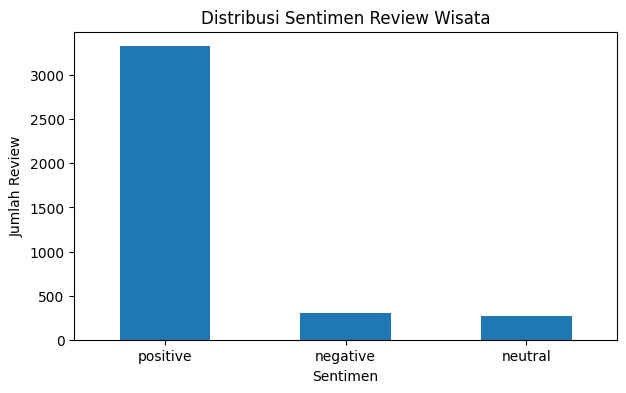

In [ ]:
import matplotlib.pyplot as plt

df["sentiment"].value_counts().plot(
    kind="bar",
    figsize=(7, 4)
)

plt.title("Distribusi Sentimen Review Wisata")
plt.xlabel("Sentimen")
plt.ylabel("Jumlah Review")
plt.xticks(rotation=0)
plt.show()

In [ ]:
df_clean = df.dropna(subset=["sentiment"]).copy()

# Mengambil kolom yang diperlukan
df_clean = df_clean[
    ["id", "lokasi", "text", "clean_text", "sentiment"]
]

# Reset index
df_clean = df_clean.reset_index(drop=True)

print("Jumlah data siap training:", len(df_clean))

print("\nDistribusi label:")
print(df_clean["sentiment"].value_counts())

Jumlah data siap training: 3896

Distribusi label:
sentiment
positive    3325
negative     302
neutral      269
Name: count, dtype: int64


In [ ]:
df_clean.to_csv(
    "sentiment_clean.csv",
    index=False,
    encoding="utf-8-sig"
)

files.download("sentiment_clean.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# **Training**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving sentiment_clean.csv to sentiment_clean (1).csv


In [ ]:
df = pd.read_csv("sentiment_clean.csv")

print("Ukuran dataset:", df.shape)

df.head()

Ukuran dataset: (3896, 5)


,id,lokasi,text,clean_text,sentiment
0,89371.0,Candi Borobudur,"pengelolaanya sudah bagus, cuma akses keluar y...","pengelolaanya sudah bagus, cuma akses keluar y...",negative
1,89372.0,Candi Borobudur,Bayar mahal2. Ada wc airnya gak ada. Sampel mu...,bayar mahal2. ada wc airnya gak ada. sampel mu...,negative
2,89374.0,Candi Borobudur,susana disana saya tidak pernah merasakan bosa...,susana disana saya tidak pernah merasakan bosa...,positive
3,89375.0,Candi Borobudur,"Htm cukup mahal untuk ukuran candi,","htm cukup mahal untuk ukuran candi,",negative
4,89377.0,Candi Borobudur,"Sebagai salah satu warisan dunia, borobudur me...","sebagai salah satu warisan dunia, borobudur me...",neutral


In [ ]:
print("Distribusi sentimen:")
print(df["sentiment"].value_counts())

print("\nPersentase sentimen:")
print(df["sentiment"].value_counts(normalize=True) * 100)

Distribusi sentimen:
sentiment
positive    3325
negative     302
neutral      269
Name: count, dtype: int64

Persentase sentimen:
sentiment
positive    85.343943
negative     7.751540
neutral      6.904517
Name: proportion, dtype: float64


In [ ]:
X = df["clean_text"]
y = df["sentiment"]

print("Jumlah fitur:", len(X))
print("Jumlah label:", len(y))

Jumlah fitur: 3896
Jumlah label: 3896


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Jumlah data training:", len(X_train))
print("Jumlah data testing:", len(X_test))

Jumlah data training: 3116
Jumlah data testing: 780


In [ ]:
model = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            max_features=10000,
            ngram_range=(1, 2),
            min_df=2,
            sublinear_tf=True
        )
    ),
    (
        "classifier",
        LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=42
        )
    )
])

In [ ]:
model.fit(X_train, y_train)

print("Training model berhasil!")

Training model berhasil!


In [ ]:
y_pred = model.predict(X_test)

hasil_prediksi = pd.DataFrame({
    "Review": X_test,
    "Sentimen Aktual": y_test,
    "Sentimen Prediksi": y_pred
})

hasil_prediksi.head(10)

,Review,Sentimen Aktual,Sentimen Prediksi
1431,very wonderful place,positive,positive
716,kenangan dng teman2 fak. ekonomi upn veteran y...,positive,positive
2527,"terbaru, saya pergi d bulan juni 2019. biaya m...",positive,negative
222,situs purbakala dgn pengurusnya yg perhatian d...,positive,negative
537,jangan lupa bawa air mineral karna bener2 pana...,negative,negative
2473,terbangunnya candi ini tidak lepas dari kisah ...,positive,positive
3794,i went here to watch the ramayana ballet show....,positive,positive
3450,the best place after borobudur temple,positive,positive
2615,"bagus sih, sayang harus muter jauh banget kalo...",negative,negative
1689,borobudur temple is one of the unesco heritage...,positive,positive


In [ ]:
accuracy = accuracy_score(y_test, y_pred)

macro_f1 = f1_score(
    y_test,
    y_pred,
    average="macro"
)

print("Accuracy Score:", round(accuracy, 4))
print("Macro F1-Score:", round(macro_f1, 4))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=["negative", "neutral", "positive"],
        zero_division=0
    )
)

Accuracy Score: 0.8423
Macro F1-Score: 0.657

Classification Report:
              precision    recall  f1-score   support

    negative       0.57      0.82      0.67        60
     neutral       0.33      0.48      0.39        54
    positive       0.95      0.87      0.91       666

    accuracy                           0.84       780
   macro avg       0.62      0.72      0.66       780
weighted avg       0.87      0.84      0.85       780



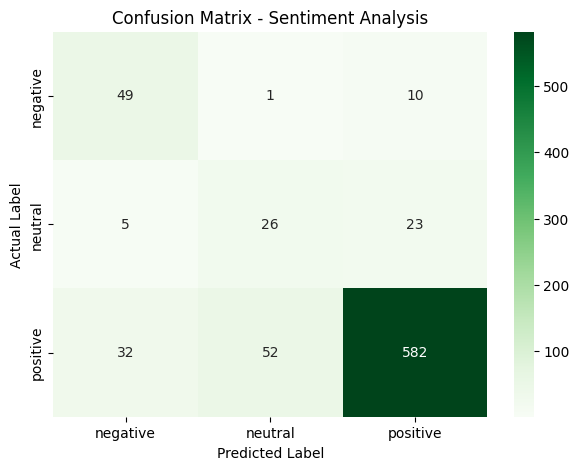

In [ ]:
labels = ["negative", "neutral", "positive"]

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=labels
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=labels,
    yticklabels=labels
)

plt.title("Confusion Matrix - Sentiment Analysis")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()

In [ ]:
contoh_review = [
    "Tempat wisata sangat indah dan pelayanannya bagus",
    "Harga tiket mahal dan fasilitasnya sangat buruk",
    "Tempat wisata ini biasa saja"
]

hasil = model.predict(contoh_review)

for review, sentimen in zip(contoh_review, hasil):
    print("Review:", review)
    print("Prediksi:", sentimen)
    print("-" * 50)

Review: Tempat wisata sangat indah dan pelayanannya bagus
Prediksi: positive
--------------------------------------------------
Review: Harga tiket mahal dan fasilitasnya sangat buruk
Prediksi: negative
--------------------------------------------------
Review: Tempat wisata ini biasa saja
Prediksi: positive
--------------------------------------------------


In [ ]:
joblib.dump(model, "model_sentiment.pkl")

print("Model berhasil disimpan!")

Model berhasil disimpan!


In [ ]:
files.download("model_sentiment.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import sklearn
print(sklearn.__version__)

1.6.1
